In [1]:
import scanpy as sc
import pandas as pd

import sys, os

import matplotlib.pyplot as plt
import palettable
from pathlib import Path
_p = Path(".").resolve()
while not (_p / "src" / "config.py").exists() and _p != _p.parent:
    _p = _p.parent
sys.path.insert(0, str(_p))
from src.config import ANALYSIS_DIR


In [ ]:
import os, sys
from pathlib import Path
sys.path.insert(0, str(Path("../..").resolve()))
# Figures used to land in data/figures/ via os.chdir; save them with the other marker plots.
from src.config import FIGURES_DIR
sc.settings.figdir = str(FIGURES_DIR / "marker-genes/d4-as")

In [ ]:
from src.markers import cell_type_markers

In [4]:

d4_as_dz_clustered = sc.read_h5ad(ANALYSIS_DIR / "data-objects/clustered/clustered_egfDuod_D4_AS_DZ.h5ad")

In [5]:
d4_as_dz_clustered

AnnData object with n_obs × n_vars = 64956 × 27680
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'freemuxlet.identity', 'participant', 'Condition', 'Time_point', 'Treatment', 'ident', 'leiden'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'X_name', 'hvg', 'log1p'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [5]:
import scanpy as sc
import numpy as np
import pandas as pd

adata = d4_as_dz_clustered  # <-- or your AnnData
cluster_key = "leiden"         # change if you used a different key

# Example markers dict:
# markers = {"Stem/ISC": ["LGR5", "ASCL2"], "Enterocyte": ["ALPI","APOA1"], ...}
# (Use your own dict here)
markers = cell_type_markers

# — ensure leiden is categorical & optional dendrogram ordering —
adata.obs[cluster_key] = adata.obs[cluster_key].astype("category")
sc.tl.dendrogram(adata, groupby=cluster_key)  # enables consistent ordering across plots

# — keep only genes present in adata.var_names (case-sensitive) —
varset = set(adata.var_names)
filtered_markers = {k: [g for g in v if g in varset] for k, v in markers.items()}
missing = {k: sorted(set(v) - varset) for k, v in markers.items() if any(g not in varset for g in v)}

# (optional) quick notice in notebook:
print("Missing genes (ignored):")
for k, lst in missing.items():
    if lst: print(f"  {k}: {', '.join(lst)}")

# If you prefer uppercase matching, uncomment this mapping:
# name_map = {g.upper(): g for g in adata.var_names}
# filtered_markers = {k: [name_map[g] for g in v if g.upper() in name_map] for k,v in markers.items()}


Missing genes (ignored):
  Secretory PCs: ATOH1


categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.
categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.


{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'size_legend_ax': <Axes: title={'center': 'Fraction of cells\nin group (%)'}>,
 'color_legend_ax': <Axes: title={'center': 'Mean expression\nin group'}>}

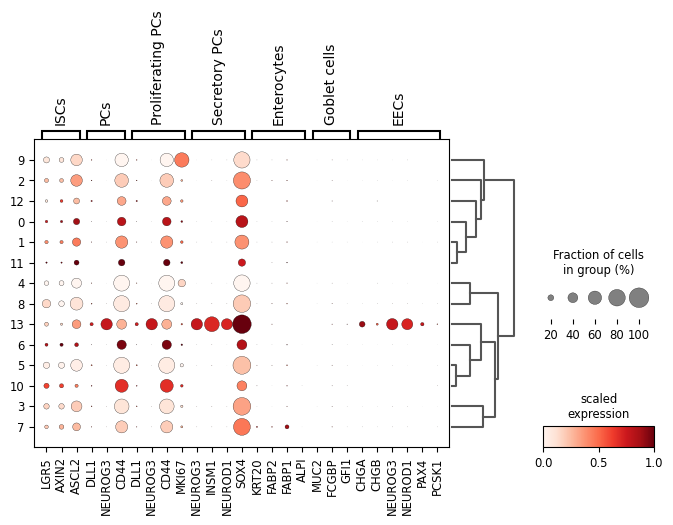

In [7]:
sc.pl.dotplot(
    adata,
    filtered_markers,              # dict[group] = list of genes
    groupby=cluster_key,
    dendrogram=True,               # uses the sc.tl.dendrogram result
    standard_scale="var",          # scale per gene for comparability
    mean_only_expressed=True,      # makes size reflect % expressing, color = mean
    swap_axes=False,               # clusters on x-axis (set True to flip)
    show=False,
    colorbar_title="scaled\nexpression",
    figsize=(8, 4)
)
# Save exactly like Scanpy expects (relative to sc.settings.figdir if set)
sc.pl.dotplot(
    adata,
    filtered_markers,
    groupby=cluster_key,
    dendrogram=True,
    standard_scale="var",
    mean_only_expressed=True,
    show=False,
    save="_markers_by_leiden_dotplot.pdf"   # yields e.g. 'figures/dotplot_markers_by_leiden_dotplot.pdf'
)


categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.


/opt/anaconda3/envs/single-cell-env/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:82: FutureWarning: `scale` is deprecated, use `density_norm` instead
  return fn(*args_all, **kw)


categories: 0, 1, 2, etc.
var_group_labels: ISCs, PCs, Proliferating PCs, etc.


/opt/anaconda3/envs/single-cell-env/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:82: FutureWarning: `scale` is deprecated, use `density_norm` instead
  return fn(*args_all, **kw)


{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'gene_group_ax': <Axes: >,
 'color_legend_ax': <Axes: title={'center': 'Median expression\nin group'}>}

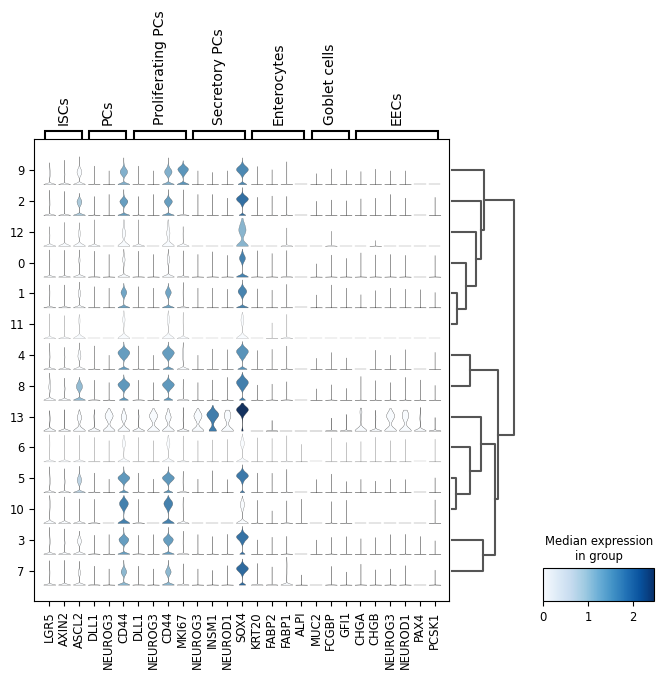

In [8]:
sc.pl.stacked_violin(
    adata,
    filtered_markers,
    groupby=cluster_key,
    dendrogram=True,
    scale="width",
    swap_axes=False,
    show=False,
    figsize=(8, 6)
)
sc.pl.stacked_violin(
    adata,
    filtered_markers,
    groupby=cluster_key,
    dendrogram=True,
    scale="width",
    swap_axes=False,
    show=False,
    save="_markers_by_leiden_violin.pdf"
)


[<Axes: title={'center': 'LGR5'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'AXIN2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'ASCL2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'DLL1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'NEUROG3'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'CD44'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'MKI67'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'INSM1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'NEUROD1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'SOX4'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'KRT20'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'FABP2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'FABP1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'ALPI'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'MUC2'}, xlabel='UMAP1',

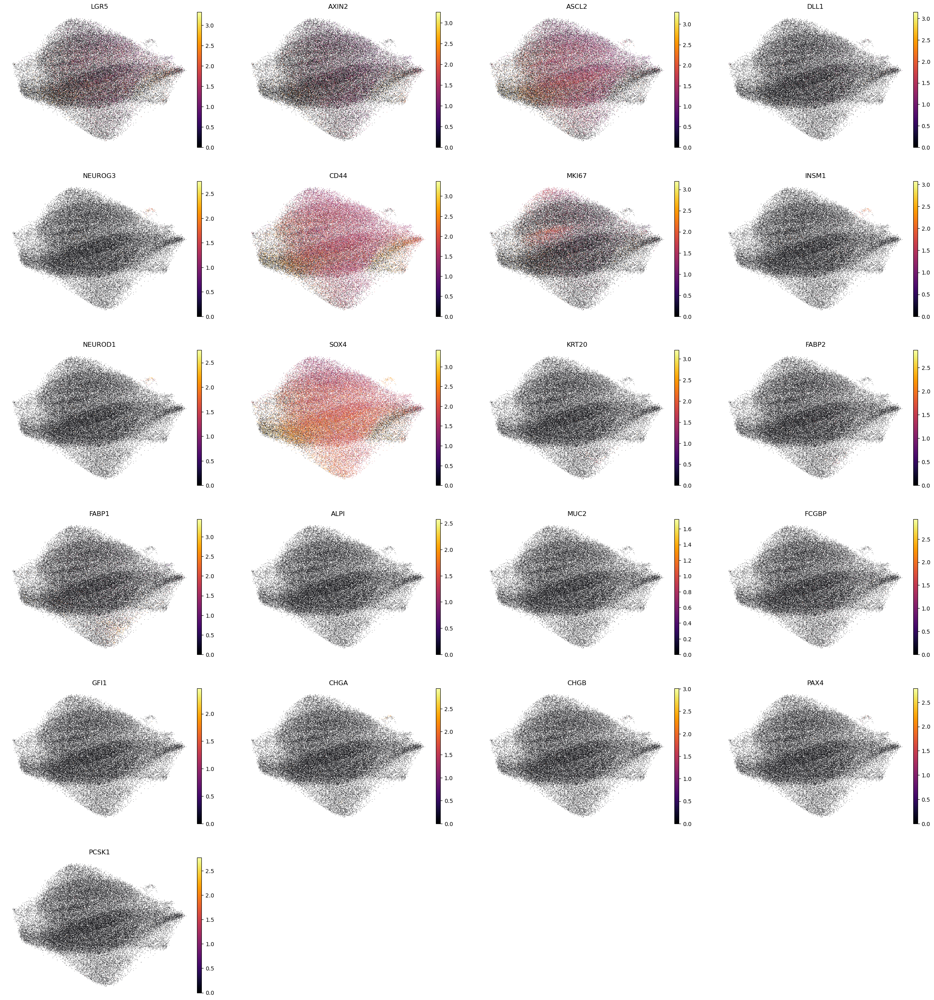

In [7]:
# Flatten your markers dict into a unique list
all_markers = []
for genes in filtered_markers.values():
    all_markers.extend(genes)
all_markers = list(dict.fromkeys(all_markers))  # preserve order, remove dups

sc.pl.umap(
    adata,
    color=all_markers,         # list of genes
    vmin=0, vmax=None,         # adjust if needed
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False
)
sc.pl.umap(
    adata,
    color=all_markers,
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False,
    save="_umap_marker_genes.pdf"
)


In [10]:
# 19: EECs

# 17: Enterocytes

#

### Those were the old clusters, for the new clustersc


In [11]:
old_key = "leiden"
new_key = "curated_labels_v1"

cluster_key = "leiden"

clusters_to_label = {
    "19": "EECs",
    "17": "Enterocytes",
}


In [12]:
adata.obs[new_key] = adata.obs[old_key].astype(str).copy()

# apply mapping only where specified; leave others as-is
mask = adata.obs[cluster_key].isin(clusters_to_label.keys())
adata.obs.loc[mask, new_key] = adata.obs.loc[mask, cluster_key].map(clusters_to_label).values

## Plot the panels of marker genes, on the UMAP

In [9]:
ISC_markers = cell_type_markers['ISCs']    
PC_markers = cell_type_markers['PCs'] 
Proliferating_PC_markers = cell_type_markers['Proliferating PCs']
Enterocyte_markers = cell_type_markers['Enterocytes']
Goblet_markers = cell_type_markers['Goblet cells']
EEC_markers = cell_type_markers['EECs']


Secretory_PC_markers = ["NEUROG3", "INSM1", "NEUROD1", "SOX4", "ATOH1"]
More_Isc_markers = ["BMI1", "EPHB2", "SOX9", "PROM1"]


#### ISC markers

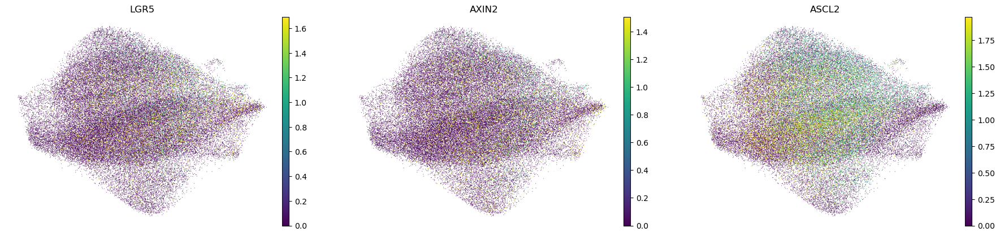

In [10]:

present = [g for g in ISC_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False,
    save="_umap_marker_genes.pdf"
)

#### More ISC markers


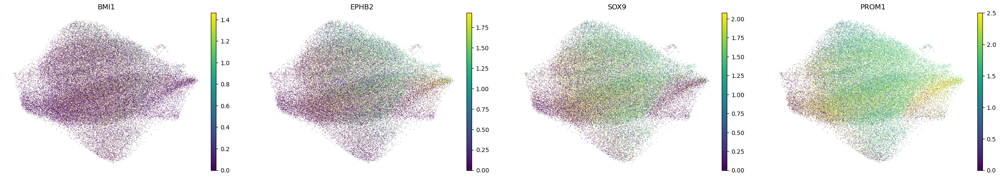

In [11]:


present = [g for g in More_Isc_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False,
        save="_umap_marker_genes.pdf"
)

[<Axes: title={'center': 'BMI1'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'EPHB2'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'SOX9'}, xlabel='UMAP1', ylabel='UMAP2'>,
 <Axes: title={'center': 'PROM1'}, xlabel='UMAP1', ylabel='UMAP2'>]

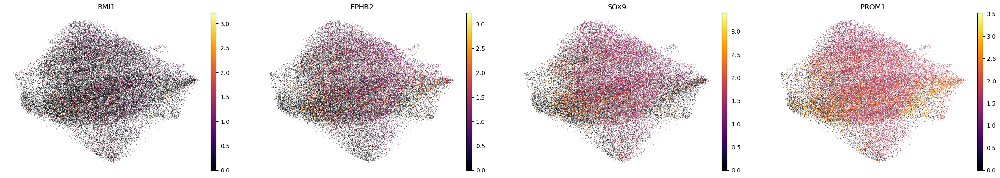

In [16]:
sc.pl.umap(
    adata,
    color=More_Isc_markers,         # list of genes
    vmin=0, vmax=None,         # adjust if needed
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False
)



sc.pl.umap(
    adata,
    color=More_Isc_markers,
    ncols=4,
    cmap="inferno",
    frameon=False,
    show=False,
    save="_umap_ISC_marker_genes.pdf"
)

/opt/anaconda3/envs/single-cell-env/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:82: FutureWarning: `scale` is deprecated, use `density_norm` instead
  return fn(*args_all, **kw)
/opt/anaconda3/envs/single-cell-env/lib/python3.11/site-packages/legacy_api_wrap/__init__.py:82: FutureWarning: `scale` is deprecated, use `density_norm` instead
  return fn(*args_all, **kw)


{'mainplot_ax': <Axes: >,
 'group_extra_ax': <Axes: >,
 'color_legend_ax': <Axes: title={'center': 'Median expression\nin group'}>}

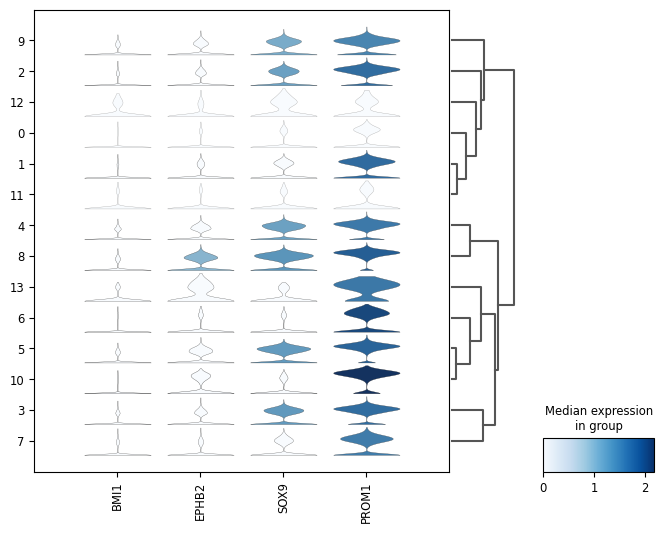

In [17]:
sc.pl.stacked_violin(
    adata,
    More_Isc_markers,
    groupby=cluster_key,
    dendrogram=True,
    scale="width",
    swap_axes=False,
    show=False,
    figsize=(8, 6)
)
sc.pl.stacked_violin(
    adata,
    More_Isc_markers,
    groupby=cluster_key,
    dendrogram=True,
    scale="width",
    swap_axes=False,
    show=False,
    save="_more_isc_markers_by_leiden_violin.pdf"
)


### Progenitor cells

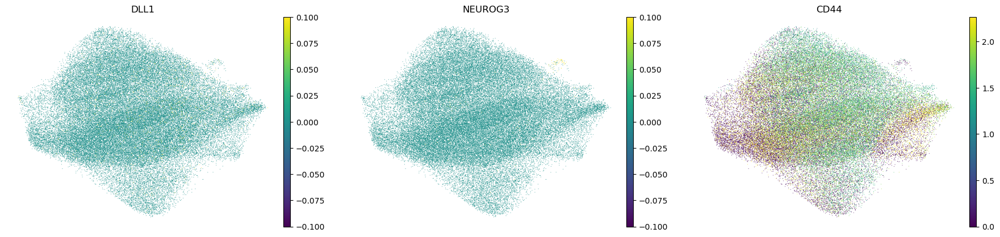

In [13]:


present = [g for g in PC_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False,
    save="_umap_marker_genes.pdf"
)

### Proliferating progenitor cells

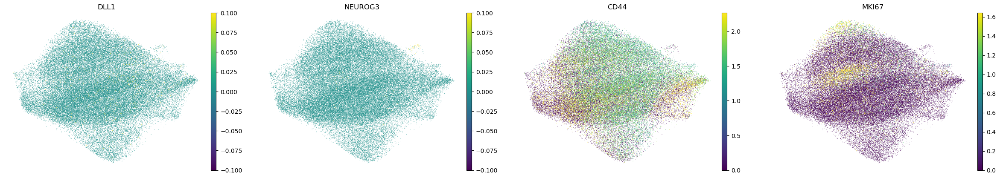

In [15]:


present = [g for g in Proliferating_PC_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False,
    save="_umap_marker_genes.pdf"

)

### Enterocyte markers


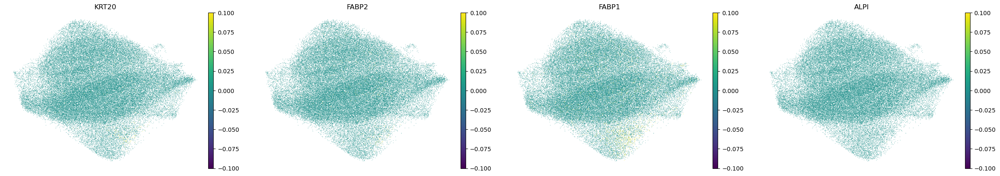

In [16]:



present = [g for g in Enterocyte_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False,
    save="_umap_marker_genes.pdf"
)


### Goblet markers

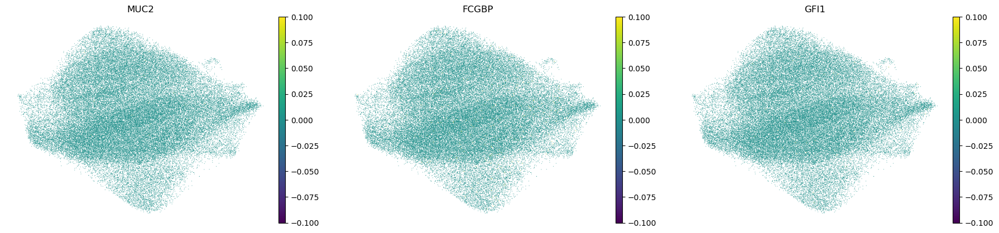

In [17]:



present = [g for g in Goblet_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False,
    save="_umap_marker_genes.pdf"

)


### Enteroendocrine markers

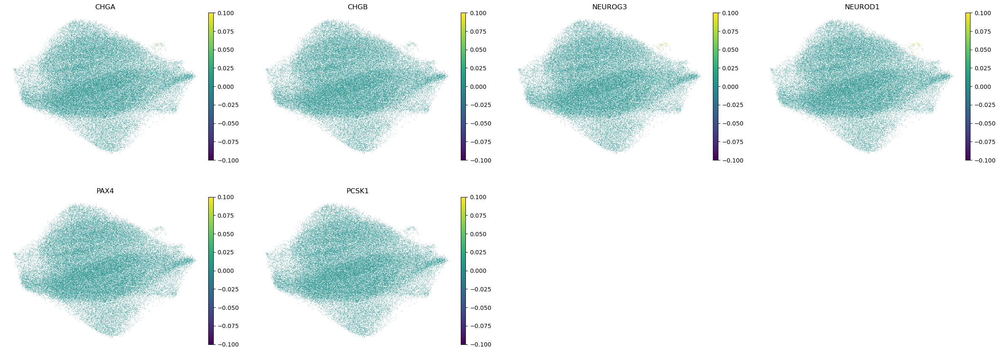

In [18]:



present = [g for g in EEC_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p95",            # nicer dynamic range
    frameon=False,
    save="_umap_marker_genes.pdf"

)


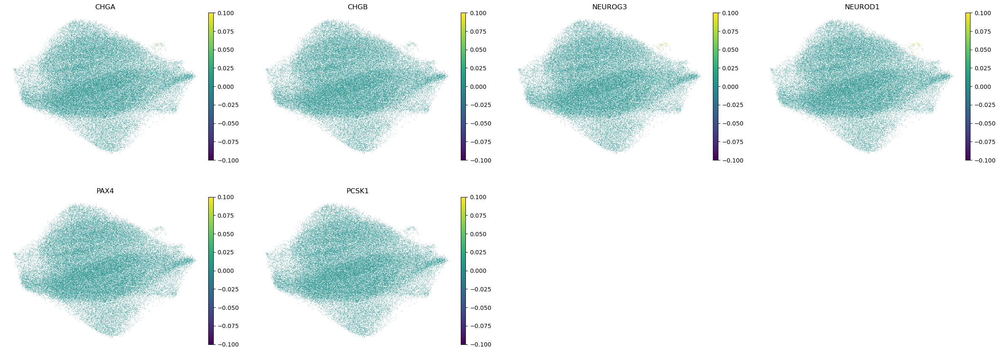

In [23]:



present = [g for g in EEC_markers
           if (hasattr(adata, "raw") and adata.raw is not None and g in adata.raw.var_names) or
              (g in adata.var_names)]

sc.pl.umap(
    adata,
    color=present,
    ncols=4,          # show expression from .raw if you froze it
    vmax="p90",            # nicer dynamic range
    frameon=False
)
